<a href="https://colab.research.google.com/github/nicolemaracaja/laboratorios_LLM/blob/main/atividade_ngramas_nicole_maracaja_123111413.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Atividade Prática — Modelos de Linguagem N-Grama do Zero

**Disciplina:** Modelos de Linguagem de Grande Escala — UFCG
**Prof.:** Leandro B. Marinho

## Objetivo
Implementar **do zero** (sem NLTK, spaCy, KenLM etc.) modelos de linguagem **unigrama, bigrama e trigrama**, treiná-los em um livro do **Projeto Gutenberg** e comparar os modelos pela **perplexidade** no conjunto de teste.

## Regras
- Só é permitido usar a biblioteca padrão do Python (`re`, `math`, `random`, `collections`, `urllib`) e `matplotlib` para os gráficos.
- **Vocês podem usar IA (ChatGPT, Claude, Copilot etc.) para gerar e ajustar o código.** Em compensação:
  1. todas as células de **verificação** (`assert`) precisam passar;
  2. vocês devem conseguir **explicar qualquer trecho** do código entregue;
  3. preencham a seção **"Declaração de uso de IA"** no final do notebook.
- Os trechos marcados com `# TODO` precisam ser implementados. Não altere as células de verificação.

## Roteiro
1. Carregar e limpar um livro do Gutenberg
2. Segmentar em sentenças e tokenizar
3. Separar treino / validação / teste e tratar palavras fora do vocabulário (`<UNK>`)
4. Implementar a classe `NGramLM` (contagens + MLE + suavização add-k)
5. Calcular a perplexidade de unigrama, bigrama e trigrama
6. Ajustar `k` na validação e implementar interpolação linear
7. Gerar texto no estilo Shannon
8. Responder às questões de análise


## 0. Imports e configuração

In [ ]:
import os
import re
import math
import random
import urllib.request
from collections import Counter

import matplotlib.pyplot as plt

SEED = 42
random.seed(SEED)

## 1. Carregando um livro do Projeto Gutenberg

Sugestão: **Dom Casmurro**, de Machado de Assis (ID `55752`). Vocês podem escolher outro livro em português (ou em outro idioma) — basta trocar o ID em https://www.gutenberg.org. Prefiram livros longos (pelo menos ~50 mil palavras).

Os arquivos do Gutenberg têm um **cabeçalho** e um **rodapé** de licença que precisam ser removidos. Eles ficam antes da linha `*** START OF THE PROJECT GUTENBERG EBOOK ... ***` e depois da linha `*** END OF THE PROJECT GUTENBERG EBOOK ... ***`.

> Se não houver internet, baixe o `.txt` manualmente e coloque-o na mesma pasta do notebook com o nome `livro.txt`.

In [ ]:
import os
import re
import urllib.request

LIVRO_ID = 55752  # Dom Casmurro
URL = f"https://www.gutenberg.org/cache/epub/{LIVRO_ID}/pg{LIVRO_ID}.txt"
CAMINHO_LOCAL = "livro.txt"

def carregar_livro(url, caminho_local=CAMINHO_LOCAL):
    """Lê o livro do disco se existir; senão, baixa do Gutenberg e salva uma cópia local."""

    if os.path.exists(caminho_local):
        with open(caminho_local, "r", encoding="utf-8") as f:
            texto = f.read()
    else:
        try:
            urllib.request.urlretrieve(url, caminho_local)

            with open(caminho_local, "r", encoding="utf-8") as f:
                texto = f.read()

        except Exception as e:
            print(f"Erro ao baixar o livro: {e}")
            return None

    return texto

def extrai_nome_livro(texto_bruto):
  """Extrai o nome do livro a partir do cabeçalho do Gutenberg."""

  if texto_bruto is None:
    return None

  # Marcador para procurar pelo nome do livro
  match = re.search(
        r"\*\*\* START OF THE PROJECT GUTENBERG EBOOK (.*?) \*\*\*",
        texto_bruto
    )

  if match:
      return match.group(1).strip()

  return None

def remover_cabecalho_rodape(texto_bruto):
    """Retorna apenas o conteúdo do livro, sem o cabeçalho e o rodapé do Gutenberg.
    Dica: use re.search para achar as linhas '*** START OF ...' e '*** END OF ...'."""

    nome_livro = extrai_nome_livro(texto_bruto)

    if nome_livro is None:
        return texto_bruto

    marcador_inicio = (
        r"\*\*\* START OF THE PROJECT GUTENBERG EBOOK "
        + re.escape(nome_livro)
        + r" \*\*\*"
    )

    marcador_fim = (
        r"\*\*\* END OF THE PROJECT GUTENBERG EBOOK "
        + re.escape(nome_livro)
        + r" \*\*\*"
    )

    inicio_match = re.search(
        marcador_inicio,
        texto_bruto,
        re.IGNORECASE
    )

    fim_match = re.search(
        marcador_fim,
        texto_bruto,
        re.IGNORECASE
    )

    if inicio_match and fim_match:
        inicio = inicio_match.end()
        fim = fim_match.start()
        return texto_bruto[inicio:fim].strip()

texto_bruto = carregar_livro(URL)
texto = remover_cabecalho_rodape(texto_bruto)
print(f"Caracteres (bruto): {len(texto_bruto):,} | após limpeza: {len(texto):,}")
print(texto[:500])

Caracteres (bruto): 400,944 | após limpeza: 381,375
DOM CASMURRO

POR

MACHADO DE ASSIS

DA ACADEMIA BRAZILEIRA

H. GARNIER, LIVREIRO-EDITOR

RUA MOREIRA CEZAR, 71

RIO DE JANEIRO

6, RUE DES SAINTS-PÈRES, 6

PARIZ




I

Do titulo.

Uma noite destas, vindo da cidade para o Engenho Novo, encontrei no
trem da Central um rapaz aqui do bairro, que eu conheço de vista e
de chapéo. Comprimentou-me, sentou-se ao pé de mim, falou da lua e
dos ministros, e acabou recitando-me versos. A viagem era curta, e os
versos póde ser que não fossem inteiramente ma


In [ ]:
# Verificação — não altere
assert "START OF" not in texto.upper()[:2000], "O cabeçalho do Gutenberg não foi removido"
assert "END OF THE PROJECT GUTENBERG" not in texto.upper(), "O rodapé do Gutenberg não foi removido"
assert len(texto) > 100_000, "Texto muito curto: escolha um livro maior"
print("OK")

OK


## 2. Segmentação em sentenças e tokenização

Implemente:
- `segmentar_sentencas(texto)`: divide o texto em sentenças (uma regra simples com `re.split` em `.`, `!`, `?` e `…` já basta; comente as limitações nas questões).
- `tokenizar(sentenca)`: converte para minúsculas e devolve a lista de palavras. Decidam e **justifiquem** se vão manter a pontuação como token. A solução de referência mantém só palavras (inclusive acentuadas e com hífen, como *disse-lhe*).

Descarte sentenças vazias.

In [ ]:
def segmentar_sentencas(texto):
  """Divide o texto em sentenças usando . ! ? e ... como delimitadores.
  Também descarta sentenças que ficaram vazias."""
  sentencas = re.split(r'[.!?…]+', texto)
  sentencas = [s.strip() for s in sentencas if s.strip()]

  return sentencas

def tokenizar(sentenca):
  """Converte a sentença em minúsculas e retorna somente as palavras
  como tokens."""
  sentenca = sentenca.lower()
  tokens = re.findall(r'\b\w+(?:-\w+)*\b', sentenca)
  return tokens

sentencas_brutas = segmentar_sentencas(texto)
sentencas = [tokenizar(s) for s in sentencas_brutas]
sentencas = [s for s in sentencas if len(s) > 0]

n_tokens = sum(len(s) for s in sentencas)
n_tipos = len(set(w for s in sentencas for w in s))

print(f"Sentenças: {len(sentencas):,} | tokens: {n_tokens:,} | tipos: {len(set(w for s in sentencas for w in s)):,}")
print(sentencas[:3])

Sentenças: 4,565 | tokens: 65,855 | tipos: 9,482
[['dom', 'casmurro', 'por', 'machado', 'de', 'assis', 'da', 'academia', 'brazileira', 'h'], ['garnier', 'livreiro-editor', 'rua', 'moreira', 'cezar', '71', 'rio', 'de', 'janeiro', '6', 'rue', 'des', 'saints-pères', '6', 'pariz', 'i', 'do', 'titulo'], ['uma', 'noite', 'destas', 'vindo', 'da', 'cidade', 'para', 'o', 'engenho', 'novo', 'encontrei', 'no', 'trem', 'da', 'central', 'um', 'rapaz', 'aqui', 'do', 'bairro', 'que', 'eu', 'conheço', 'de', 'vista', 'e', 'de', 'chapéo']]


In [ ]:
# Verificação — não altere
assert tokenizar("Ela disse-lhe: Não!")[0] == "ela", "Converta para minúsculas"
assert len(segmentar_sentencas("Oi. Tudo bem? Sim!")) == 3
assert all(isinstance(s, list) and len(s) > 0 for s in sentencas)
print("OK")

OK


### 2.1 Lei de Zipf (rápido)
Plote, em escala log-log, a frequência das palavras em função do rank. O gráfico se aproxima de uma reta? O que acontece nas pontas?

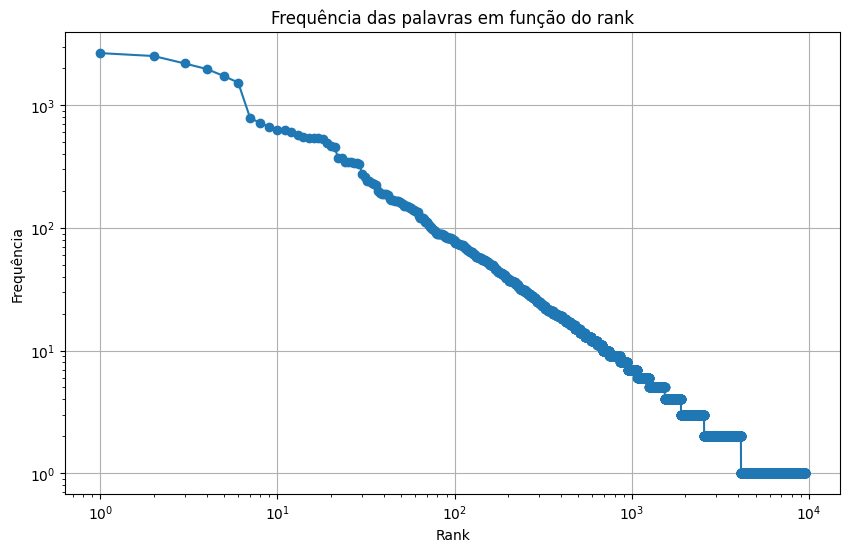

In [ ]:
freq = Counter(w for s in sentencas for w in s)

freq_ordenadas = sorted(freq.items(), key=lambda x: x[1], reverse=True)

palavras, frequencias = zip(*freq_ordenadas)

ranks = range(1, len(freq_ordenadas) + 1)
frequencias = [f for palavra, f in freq_ordenadas]

plt.figure(figsize=(10, 6))
plt.loglog(ranks, frequencias, marker='o', linestyle='-')
plt.xlabel('Rank')
plt.ylabel('Frequência')
plt.title('Frequência das palavras em função do rank')
plt.grid(True)
plt.show()

O gráfico apresenta um comportamento aproximadamente linear em escala log-log, principalmente na região central. As palavras de menor rank possuem frequências muito maiores, enquanto diminui conforme o rank aumenta. Nas pontas do gráfico, há um maior afastamento da tendência, principalmente nos ranks mais altos, por causa da grande quantidade de palavras raras.

## 3. Treino, validação e teste + tratamento de `<UNK>`

1. Embaralhe as sentenças com `SEED` e separe **80% treino / 10% validação / 10% teste**.
2. Construa o vocabulário **apenas com o treino**. Palavras que aparecem **menos de `MIN_FREQ` vezes** no treino viram `<UNK>`.
3. Substitua por `<UNK>` as palavras de validação e teste que não estão no vocabulário.

> Por que isso é necessário? Sem `<UNK>`, qualquer palavra nova no teste tem probabilidade zero, e a perplexidade vai para infinito (slide *Zeros*).

In [ ]:
MIN_FREQ = 2
UNK = "<UNK>"

def dividir(sentencas, prop_treino=0.8, prop_val=0.1, seed=SEED):
    """Embaralha as sentenças e divide em treino, validação e teste."""

    sentencas_embaralhadas = sentencas.copy()
    random.seed(seed)
    random.shuffle(sentencas_embaralhadas)

    n = len(sentencas_embaralhadas)
    fim_treino = int(n * prop_treino)
    fim_val = fim_treino + int(n * prop_val)

    # Faz a divisão 80% 10% e 10%
    treino = sentencas_embaralhadas[:fim_treino]
    val = sentencas_embaralhadas[fim_treino:fim_val]
    teste = sentencas_embaralhadas[fim_val:]

    return treino, val, teste

def construir_vocab(treino, min_freq=MIN_FREQ):
    """Constrói o vocabulário usando somente as palavras do treino."""

    freq = Counter(w for s in treino for w in s)
    vocab = {palavra for palavra, frequencia in freq.items() if frequencia >= min_freq}
    vocab.add(UNK)

    return vocab

def substituir_unk(sentencas, vocab):
    """Substitui as palavras de sentencas que não estão no vocab por <UNK>."""

    resultado = []
    for sentenca in sentencas:
        nova_sentenca = [palavra if palavra in vocab else UNK for palavra in sentenca]
        resultado.append(nova_sentenca)

    return resultado

treino_raw, val_raw, teste_raw = dividir(sentencas)
vocab = construir_vocab(treino_raw)
treino = substituir_unk(treino_raw, vocab)
val = substituir_unk(val_raw, vocab)
teste = substituir_unk(teste_raw, vocab)

taxa_unk = sum(w == UNK for s in teste for w in s) / sum(len(s) for s in teste)
print(f"Treino: {len(treino):,} | Val: {len(val):,} | Teste: {len(teste):,} sentenças")
print(f"Vocabulário: {len(vocab):,} palavras (+ <UNK>) | taxa de <UNK> no teste: {taxa_unk:.2%}")

Treino: 3,652 | Val: 456 | Teste: 457 sentenças
Vocabulário: 3,495 palavras (+ <UNK>) | taxa de <UNK> no teste: 14.83%


In [ ]:
# Verificação — não altere
assert len(treino) + len(val) + len(teste) == len(sentencas)
assert abs(len(treino) / len(sentencas) - 0.8) < 0.01
assert all(w in vocab or w == UNK for s in teste for w in s)
print("OK")

OK


## 4. A classe `NGramLM`

Implemente um modelo n-grama genérico (funciona para `n = 1, 2, 3, ...`):

- **Padding:** cada sentença vira `['<s>'] * (n-1) + sentença + ['</s>']`. Assim, no trigrama, a primeira palavra é condicionada em `(<s>, <s>)`.
- **Contagens:** `C(contexto, w)` e `C(contexto)`, em que o contexto é a tupla das `n-1` palavras anteriores (para o unigrama, o contexto é a tupla vazia `()`).
- **Vocabulário do modelo** `V`: palavras do treino + `<UNK>` + `</s>` (o `<s>` **não** entra, porque nunca é previsto).
- **Probabilidade com suavização add-k** (com `k = 0` você obtém a MLE; com `k = 1`, Laplace):

$$P(w \mid \text{ctx}) = \frac{C(\text{ctx}, w) + k}{C(\text{ctx}) + k\,|V|}$$

- **Log-probabilidade de uma sentença**: soma dos `log P` de cada palavra **e do `</s>`**.
- **Perplexidade** de um conjunto de sentenças, com $N$ = total de palavras previstas (incluindo os `</s>`):

$$PP = \exp\left(-\frac{1}{N}\sum \log P(w_i \mid \text{ctx}_i)\right)$$

Se alguma probabilidade for zero, a perplexidade deve ser `float('inf')`.

In [ ]:
BOS, EOS = "<s>", "</s>"


class NGramLM:
    def __init__(self, n, k=0.0):
        self.n = n
        self.k = k
        self.ngram_counts = Counter()
        self.context_counts = Counter()
        self.vocab = set()

    def _padding(self, sentenca):
        """Adiciona marcadores de início e fim da sentença."""
        return [BOS] * (self.n - 1) + sentenca + [EOS]

    def _ngramas(self, sentenca):
        """Gera pares (contexto, palavra) de uma sentença já com padding."""

        pares = []

        for i in range(self.n - 1, len(sentenca)):
            contexto = tuple(sentenca[i - self.n + 1:i])
            palavra = sentenca[i]
            pares.append((contexto, palavra))

        return pares

    def fit(self, sentencas):
        """Treina o modelo contando n-gramas e contextos."""

        self.ngram_counts = Counter()
        self.context_counts = Counter()
        self.vocab = set()

        for sentenca in sentencas:
            self.vocab.update(sentenca)
            self.vocab.add(EOS)
            sentenca_padded = self._padding(sentenca)

            for contexto, palavra in self._ngramas(sentenca_padded):
                self.ngram_counts[(contexto, palavra)] += 1
                self.context_counts[contexto] += 1

        self.vocab.add("<UNK>")
        return self

    @property
    def V(self):
        return len(self.vocab)

    def prob(self, w, ctx):
      """Calcula P(w | contexto) usando suavização add-k."""
      # TODO: estimativa add-k (k=0 -> MLE). Cuidado com contexto nunca visto (denominador 0).

      ctx = tuple(ctx)

      contagem_ngram = self.ngram_counts[(ctx, w)]
      contagem_contexto = self.context_counts[ctx]

      numerador = contagem_ngram + self.k
      denominador = contagem_contexto + self.k * self.V

      if denominador == 0:
        return 0.0

      return numerador / denominador

    def logprob_sentenca(self, sentenca):
      """Calcula a log-probabilidade de uma sentença, incluindo </s>."""
        # TODO: soma de log P, incluindo o </s>. Retorne -inf se alguma prob for 0.

      sentenca_padded = self._padding(sentenca)
      logprob = 0.0

      for contexto, palavra in self._ngramas(sentenca_padded):
        prob_palavra = self.prob(palavra, contexto)
        if prob_palavra == 0:
          return float('-inf')
        logprob += math.log(prob_palavra)

      return logprob

    def perplexidade(self, sentencas):
        """Calcula a perplexidade de um conjunto de sentenças."""
        soma_logprob = 0.0
        N = 0

        for sentenca in sentencas:
          logprob_sentenca = self.logprob_sentenca(sentenca)

          if logprob_sentenca == float('-inf'):
            return float('inf')

          soma_logprob += logprob_sentenca
          N += len(sentenca) + 1  # +1 para o </s>

        if N == 0:
          return float('inf')

        return math.exp(-soma_logprob / N)

### 4.1 Verificação com o corpus dos slides

Use o mini-corpus da aula (*I am Sam*). Os valores esperados são os mesmos calculados em sala.

In [ ]:
# Verificação — não altere
corpus_sam = [["I", "am", "Sam"], ["Sam", "I", "am"], ["I", "do", "not", "like", "green", "eggs", "and", "ham"]]
bg = NGramLM(2, k=0).fit(corpus_sam)

assert math.isclose(bg.prob("I", ["<s>"]), 2/3)
assert math.isclose(bg.prob("Sam", ["<s>"]), 1/3)
assert math.isclose(bg.prob("am", ["I"]), 2/3)
assert math.isclose(bg.prob("</s>", ["Sam"]), 1/2)
assert math.isclose(bg.prob("Sam", ["am"]), 1/2)
assert math.isclose(bg.prob("do", ["I"]), 1/3)

# As probabilidades de um contexto devem somar 1 (MLE e add-k)
for k in [0, 1, 0.1]:
    m = NGramLM(2, k=k).fit(corpus_sam)
    assert math.isclose(sum(m.prob(w, ["I"]) for w in m.vocab), 1.0), f"não soma 1 com k={k}"
    m3 = NGramLM(3, k=k).fit(corpus_sam)
    assert math.isclose(sum(m3.prob(w, ["<s>", "I"]) for w in m3.vocab), 1.0)

# Unigrama: P(I) = 3/17 (14 palavras + 3 </s> = 17 tokens previstos; o <s> não conta)
ug = NGramLM(1, k=0).fit(corpus_sam)
assert math.isclose(ug.prob("I", []), 3 / 17)

# MLE atribui zero a bigrama não visto -> perplexidade infinita
assert NGramLM(2, k=0).fit(corpus_sam).perplexidade([["Sam", "do", "ham"]]) == float("inf")
print("OK")

OK


## 5. Perplexidade: unigrama × bigrama × trigrama

### 5.1 MLE (sem suavização)
Treine os três modelos com `k = 0` e calcule a perplexidade no **treino** e no **teste**. Explique o que acontece.

In [ ]:
resultados_mle = {}
for n in [1, 2, 3]:
    # TODO: treine com k=0 e calcule PP no treino e no teste

    modelo = NGramLM(n, k=0)
    modelo.fit(treino)

    pp_treino = modelo.perplexidade(treino)
    pp_teste = modelo.perplexidade(teste)

    resultados_mle[n] = {"treino": pp_treino, "teste": pp_teste}

resultados_mle

{1: {'treino': 350.43539770113233, 'teste': 236.038602817044},
 2: {'treino': 32.09304993100784, 'teste': inf},
 3: {'treino': 4.5317398948740575, 'teste': inf}}

Com MLE, a perplexidade do treino tende ao infinito, já que o modelo atribui probabilidade positiva aos n-gramas observados no próprio treinamento. Já no teste, podem existir n-gramas que não aparecem no treino, recebendo probabilidade 0, fazendo com que a log-probabilidade torne-se -inf e a perplexidade tende ao infinito.

### 5.2 Suavização de Laplace (add-1)
Repita com `k = 1`.

In [ ]:
resultados_laplace = {}
for n in [1, 2, 3]:
    # TODO: treine com k=1 e calcule PP no treino e no teste

    modelo = NGramLM(n, k=1)
    modelo.fit(treino)

    pp_treino = modelo.perplexidade(treino)
    pp_teste = modelo.perplexidade(teste)

    resultados_laplace[n] = {"treino": pp_treino, "teste": pp_teste}

resultados_laplace

{1: {'treino': 352.4607188570104, 'teste': 240.62287318071378},
 2: {'treino': 609.8632608707791, 'teste': 608.4577587344703},
 3: {'treino': 1277.8731172929527, 'teste': 1942.9499259066338}}

### 5.3 Ajustando `k` na validação (add-k)
Para cada `n`, escolha o melhor `k` em `[1, 0.5, 0.1, 0.05, 0.01, 0.005, 0.001]` usando a **validação**. Depois avalie **uma única vez** no teste.

In [ ]:
KS = [1, 0.5, 0.1, 0.05, 0.01, 0.005, 0.001]
melhor_k, resultados_addk = {}, {}

for n in [1, 2, 3]:
    melhor_pp_val = float("inf")
    k_escolhido = None

    for k in KS:
        modelo = NGramLM(n, k=k)
        modelo.fit(treino)

        pp_val = modelo.perplexidade(val)

        if pp_val < melhor_pp_val:
            melhor_pp_val = pp_val
            k_escolhido = k

    melhor_k[n] = k_escolhido

    modelo_final = NGramLM(n, k=k_escolhido)
    modelo_final.fit(treino)

    pp_teste = modelo_final.perplexidade(teste)

    resultados_addk[n] = {"k": k_escolhido, "val": melhor_pp_val,"teste": pp_teste}

resultados_addk

{1: {'k': 0.001, 'val': 240.0494137154813, 'teste': 236.04236402931673},
 2: {'k': 0.01, 'val': 233.74715906917896, 'teste': 223.78388795873073},
 3: {'k': 0.005, 'val': 865.527725699839, 'teste': 868.5187754979762}}

In [ ]:
print("Melhores valores de k:")

for n in [1, 2, 3]:
    print(
        f"{n}-grama → "
        f"k = {melhor_k[n]}, "
        f"PP val = {resultados_addk[n]['val']:.2f}, "
        f"PP teste = {resultados_addk[n]['teste']:.2f}"
    )

Melhores valores de k:
1-grama → k = 0.001, PP val = 240.05, PP teste = 236.04
2-grama → k = 0.01, PP val = 233.75, PP teste = 223.78
3-grama → k = 0.005, PP val = 865.53, PP teste = 868.52


## 6. Interpolação linear

Combine os três modelos MLE:

$$\hat P(w_i \mid w_{i-2}, w_{i-1}) = \lambda_1 P(w_i) + \lambda_2 P(w_i \mid w_{i-1}) + \lambda_3 P(w_i \mid w_{i-2}, w_{i-1}), \quad \sum \lambda_j = 1$$

Escolha os λ por **busca em grade** na validação (passo de 0.1, com λ₁ > 0 para evitar zeros) e reporte a perplexidade no teste.

> Dica: para facilitar, a classe `Interpolado` pode reaproveitar `NGramLM.perplexidade`, sobrescrevendo apenas `n` e `prob`.

In [ ]:
class Interpolado(NGramLM):
    def __init__(self, modelos, lambdas):
        self.modelos, self.lambdas = modelos, lambdas
        self.n = max(m.n for m in modelos)

    def prob(self, w, ctx):
        """Calcula a probabilidade interpolada dos modelos unigrama,
        bigrama e trigrama."""

        p1 = self.modelos[0].prob(w, [])
        p2 = self.modelos[1].prob(w, [ctx[-1]])
        p3 = self.modelos[2].prob(w, list(ctx[-2]))

        return (self.lambdas[0] * p1 + self.lambdas[1] * p2 + self.lambdas[2] * p3)

mle = [NGramLM(n, k=0).fit(treino) for n in [1, 2, 3]]

melhor_pp_val = float("inf")
melhores_lambdas = None

for i in range(1, 11):
  lambda1 = i/10
  for j in range(0, 11):
    lambda2 = j/10
    lambda3 = 1.0 - lambda1 - lambda2

    if lambda3 < 0 or lambda3 > 1:
      continue

    lambdas = (lambda1, lambda2, lambda3)
    interpolado = Interpolado(mle, lambdas)

    pp_val = interpolado.perplexidade(val)

    if pp_val < melhor_pp_val:
      melhor_pp_val = pp_val
      melhores_lambdas = lambdas

modelo_interp_final = Interpolado(mle, melhores_lambdas)
pp_interp = modelo_interp_final.perplexidade(teste)

print(f"Melhores lambdas: {melhores_lambdas}")
print(f"PP validação: {melhor_pp_val:.2f}")
print(f"PP teste: {pp_interp:.2f}")

Melhores lambdas: (0.5, 0.5, 0.0)
PP validação: 137.91
PP teste: 133.34


### 6.1 Tabela e gráfico comparativo

In [ ]:
# TODO: tabela e gráfico de barras com a perplexidade no teste de cada modelo
resultados_teste = {
    "Unigrama": resultados_addk[1]["teste"],
    "Bigrama": resultados_addk[2]["teste"],
    "Trigrama": resultados_addk[3]["teste"],
    "Interpolado": pp_interp
}

print("Perplexidade no teste:")
print()

for modelo, pp in resultados_teste.items():
    print(f"{modelo:<12} {pp:.2f}")

Perplexidade no teste:

Unigrama     236.04
Bigrama      223.78
Trigrama     868.52
Interpolado  133.34


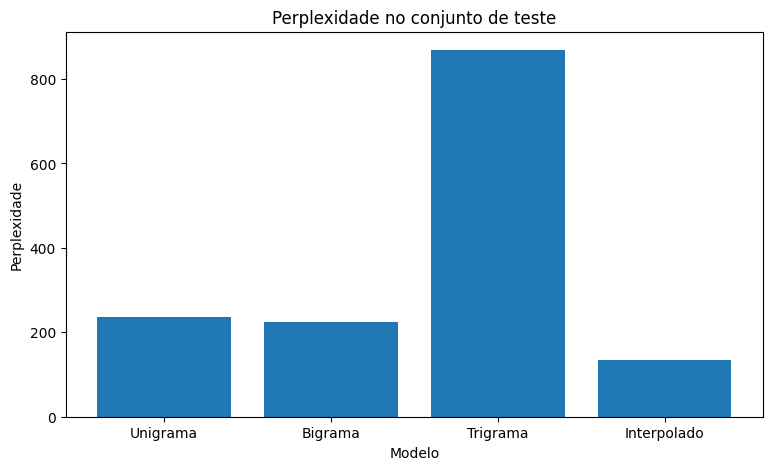

In [ ]:
modelos = list(resultados_teste.keys())
perplexidades = list(resultados_teste.values())

plt.figure(figsize=(9, 5))

plt.bar(modelos, perplexidades)

plt.xlabel("Modelo")
plt.ylabel("Perplexidade")
plt.title("Perplexidade no conjunto de teste")

plt.show()

## 7. Gerando texto no estilo Shannon

Implemente `gerar(modelo, max_palavras=30)`: comece com o contexto `<s>` (ou `<s> <s>`), sorteie a próxima palavra **proporcionalmente às contagens MLE** do contexto atual e continue até sortear `</s>`. Gere 3 frases com cada modelo (unigrama, bigrama, trigrama) e compare.

In [ ]:
def gerar(modelo, max_palavras=30, rng=random.Random(SEED)):
  """Gera uma sequência de palabvras usando amostragem proporcional às contagens
  MLE do contexto atual."""

  ctx = tuple([BOS] * (modelo.n - 1))
  palavras_geradas = []

  for _ in range(max_palavras):
    candidatos = []
    contagens = []

    for (contexto, palavra), contagem in modelo.ngram_counts.items():
      if contexto == tuple(ctx):
        candidatos.append(palavra)
        contagens.append(contagem)

    if not candidatos:
      break

    palavra_escolhida = rng.choices(candidatos, weights=contagens, k=1)[0]

    if palavra_escolhida == EOS:
      break

    palavras_geradas.append(palavra_escolhida)

    if modelo.n > 1:
      ctx = ctx[1:] + (palavra_escolhida,)

  return " ".join(palavras_geradas)

for n, m in zip([1, 2, 3], mle):
    print(f"--- {n}-grama ---")
    for _ in range(3):
        print("•", gerar(m))

--- 1-grama ---
• hão a <UNK> eu taes ninguem espiritual
• muito a e mais a e foi á e peccado ergueu-se a velho mamãe era que padecimentos era
• 
--- 2-grama ---
• ciii a premissa antes ou lá matar
• enxugou sem me deu são bellas figuras antigas
• o que é provavel que de <UNK> e puro e escobar que corri ao outro officio
--- 3-grama ---
• _ é ahi
• o protonotario elle lhe <UNK> nomes tão feios e bellos mas eu não <UNK>
• <UNK> seria perder a esperança no fundo em alguma cousa e eu <UNK> a falar com os mesmos nomes <UNK> por falta delle como de pessoa alguma


## 8. Questões de análise

Responda em células de texto, **com base nos seus resultados**:

1. O que aconteceu com a perplexidade no teste dos modelos MLE (seção 5.1)? E no treino? Explique por que o unigrama MLE não teve o mesmo problema.
2. Com Laplace (k = 1), a ordem "trigrama < bigrama < unigrama" dos slides (962 / 170 / 109) se manteve? Se não, explique o motivo, relacionando com a **esparsidade** (quantos trigramas possíveis existem, dado o tamanho do vocabulário, e quantos foram observados?).
3. Como o melhor `k` variou com `n`? Por que faz sentido que modelos de ordem maior prefiram `k` menor?
4. Compare add-k e interpolação. Quais λ foram escolhidos e o que eles dizem sobre a confiabilidade de cada modelo neste corpus?
5. Por que os hiperparâmetros (`k`, λ) foram ajustados na **validação** e não no **teste**? O que aconteceria se usássemos o teste?
6. Compare as frases geradas pelos três modelos. O que muda de um para o outro? O trigrama está "copiando" o livro? Como verificar isso?
7. Cite duas limitações da segmentação/tokenização que você usou, com exemplos do próprio livro (ex.: *Sr.*, *D.*, travessões de diálogo).
8. **(Bônus)** Troque o livro por outro autor ou época e avalie o modelo treinado em *Dom Casmurro* no novo livro. O que acontece com a perplexidade? Relacione com o slide "O Wall Street Journal não é Shakespeare".


*Respostas:*

1. No teste, os modelos MLE de maior ordem podem apresentar perplexidade infinita, porque alguns n-gramas do teste não aparecem no treinamento e recebem probabilidade 0. No treino isso não acontece porque os n-gramas avaliados foram observados durante o treinamento.
O unigrama não sofre o mesmo problema pois, após o uso de UNK, as palavras do teste pertencem ao vocabulário do modelo. Dessa forma, o modelo consegue atribuir probabilidade às palavras.
2. Não. O trigrama é muito mais esparso. Então se temos V palavras no vocabulário, existem aproximadamente V³ combinações de três palavras possíveis, mas no livro, apenas uma pequena parte dessas combinações realmente aparece. Como o trigrama possui muitas combinações possíveis que não aparecem no treinamento, Laplace precisa distribuir probabilidade também para essas combinações. Isso deixa as probabilidades menos precisas e pode aumentar a perplexidade do trigrama.
3. Os melhores valores foram k=0,001 para unigrama, k=0,01 para bigrama e k=0,005 para trigrama. Modelos de maior ordem são mais esparsos, pois possuem mais combinações possíveis. Por isso, uma suavização muito grande pode alterar muito as frequências observadas.
4. O add-k suaviza as probabilidades do modelo, enquanto a interpolação combina modelos de diferentes ordens. Os melhores pesos encontrados foram λ = 0,5; 0,5; 0,0. Assim, o unigrama e o bigrama receberam o mesmo peso, enquanto o trigrama não contribuiu para a combinação. Nesse corpus, o contexto de uma palavra foi útil, mas adicionar uma segunda palavra de contexto não melhorou o resltado.
A interpolação apresentou perplexidade 133,34 no teste, menor que o unigrama (236,04), bigrama (223,78) e trigrama (868,52).
5. Os hiperparâmetros foram ajustados na validação para que o teste pudesse ser usado apenas na avaliação final. Se k e λ fossem escolhidos usando o teste, o modelo estaria sendo ajustado aos próprios dados usados para avaliá-lo, deixando a avaliação menos confiável.
6. O unigrama gera frases mais aleatórias e sem muita relação entre as palavras, como em “muito a e mais a e foi...”, porque não considera o contexto. O bigrama produz algumas combinações mais naturais, como “o que é provável” e “eu não”, pois considera a palavra anterior. Mesmo assim, a frase completa ainda pode ficar sem sentido. O trigrama, por sua vez, consegue formar sequências mais coerentes, como “perder a esperança no fundo”, pois considera as duas palavras anteriores.
7. Uma limitação é que números são tratados como tokens, como "71" e "6" presentes nas informações editoriais do livro. Isso pode introduzir elementos que não são relevantes para o conteúdo literário. Outra limitação é que palavras com acentos e grafias antigas são mantidas exatamente como aparecem, como "chapéo", "taes" e "brazileira". Isso faz com que palavras com grafias diferentes sejam consideradas tokens diferentes, mesmo quando possuem significado equivalente na escrita atual.
8. Avaliando o modelo treinado em Dom Casmurro no livro O Cortiço, a perplexidade foi de 182,56, enquanto no teste de Dom Casmurro foi 223,78. Neste experimento, a perplexidade não aumentou no novo livro; ela foi menor. Isso mostra que a perplexidade depende das características do texto e não apenas do fato de ser outro livro. O resultado se relaciona ao slide “O Wall Street Journal não é Shakespeare”, que mostra que modelos de linguagem aprendem padrões específicos dos textos usados no treinamento e podem apresentar desempenhos diferentes quando aplicados a textos de outros autores, estilos ou domínios.

In [ ]:
# Bônus

LIVRO_NOVO_ID = 69187
URL_NOVO = f"https://www.gutenberg.org/cache/epub/{LIVRO_NOVO_ID}/pg{LIVRO_NOVO_ID}.txt"

if os.path.exists("livro_novo.txt"):
    os.remove("livro_novo.txt")

texto_novo_bruto = carregar_livro(URL_NOVO, "livro_novo.txt")
nome_livro_novo = extrai_nome_livro(texto_novo_bruto)

print("Livro encontrado no Gutenberg:", nome_livro_novo)

texto_novo = remover_cabecalho_rodape(texto_novo_bruto)

sentencas_novas = segmentar_sentencas(texto_novo)
sentencas_novas = [tokenizar(s) for s in sentencas_novas]
sentencas_novas = [s for s in sentencas_novas if len(s) > 0]

print("Sentenças:", len(sentencas_novas))
print("Tokens:", sum(len(s) for s in sentencas_novas))

# Modelo treinado em Dom Casmurro
modelo_doming = NGramLM(2, k=0.01)
modelo_doming.fit(treino)

# Substituir palavras desconhecidas por <UNK>
sentencas_novas_unk = substituir_unk(
    sentencas_novas,
    modelo_doming.vocab
)

pp_dom_casmurro = modelo_doming.perplexidade(teste)
pp_novo = modelo_doming.perplexidade(sentencas_novas_unk)

print("\nPerplexidade:")
print(f"Dom Casmurro: {pp_dom_casmurro:.2f}")
print(f"{nome_livro_novo}: {pp_novo:.2f}")

Livro encontrado no Gutenberg: O CORTIÇO
Sentenças: 5393
Tokens: 80643

Perplexidade:
Dom Casmurro: 223.78
O CORTIÇO: 182.56


## 9. Declaração de uso de IA

- Ferramenta(s) usada(s): ChatGPT e Gemini integrado ao Google Colab.
- Para quais partes: Apoio na compreensão e implementação das etapas do roteiro.
- Exemplos de prompts relevantes: "Como implementar um modelo de n-gramas do zero em Python?" ou "Como implementar geração de texto pelo método de Shannon"
- O que precisou ser corrigido ou ajustado no código gerado: Tive alguns problemas relacionados ao uso de listas e tuplas nos contextos dos n-gramas e à divisão de dados em treino, validação e teste.
- Algo que a IA errou ou explicou de forma incorreta: Nomes de variáveis inconsistentes, não usou tuplas quando era necessário, entre outros.


---
### Critérios de avaliação
| Item | Peso |
|---|---|
| Carregamento, limpeza e tokenização (seções 1–3) | 15% |
| Classe `NGramLM` correta (todas as verificações passando) | 25% |
| Perplexidade MLE / Laplace / add-k (seção 5) | 20% |
| Interpolação linear (seção 6) | 10% |
| Geração estilo Shannon (seção 7) | 5% |
| Questões de análise (seção 8) | 20% |
| Declaração de uso de IA | 5% |
